# Indian Equity Volatility Early-Warning Model

## Objective
Develop and evaluate machine-learning models that predict whether the Indian equity market will experience unusually high volatility over the next trading week, using historical market data.

## Approach
- Obtain historical NIFTY 50 market data.
- Engineer features using past market information only.
- Define a high-volatility prediction target.
- Compare a simple baseline with Logistic Regression, Random Forest, and XGBoost.
- Evaluate models using chronological validation and test data.

**Important:** The notebook reports exploratory results from chronological and walk-forward evaluation. Performance varies across market periods, and results from quarters with few high-volatility events should be interpreted cautiously. These findings do not establish future predictive performance or trading profitability.

In [3]:

%pip -q install yfinance xgboost

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# Download historical NIFTY 50 index data
ticker = "^NSEI"

data = yf.download(
    ticker,
    period="10y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise RuntimeError(
        "No market data was downloaded. Check the connection and retry; "
        "do not replace missing market data with synthetic data."
    )

# Handle possible multi-level column names returned by yfinance
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data[["Open", "High", "Low", "Close", "Volume"]].copy()
data.index = pd.to_datetime(data.index)
data = data.sort_index()
data = data[~data.index.duplicated(keep="first")]

print("Dataset shape:", data.shape)
print("First date:", data.index.min().date())
print("Last date:", data.index.max().date())
print("\nFirst five rows:")
display(data.head())

print("\nMissing values:")
display(data.isna().sum())

print("\nData types:")
display(data.dtypes)



Dataset shape: (2467, 5)
First date: 2016-10-24
Last date: 2026-10-23

First five rows:


Price,Open,High,Low,Close,Volume
Date,,,,,
2016-10-24,8709.849609,8736.950195,8684.150391,8708.950195,157100
2016-10-25,8721.700195,8722.650391,8663.450195,8691.299805,189800
2016-10-26,8657.299805,8657.299805,8596.599609,8615.250000,219300
2016-10-27,8607.099609,8624.849609,8550.250000,8615.250000,242800
2016-10-28,8625.000000,8653.750000,8581.750000,8638.000000,175500



Missing values:


,0
Price,
Open,0
High,0
Low,0
Close,0
Volume,0



Data types:


,0
Price,
Open,float64
High,float64
Low,float64
Close,float64
Volume,int64


In [4]:

print("Column names:")
print(data.columns.tolist())

print("\nIndex name:")
print(data.index.name)

print("\nFirst five rows:")
display(data.head())

print("\nSummary statistics:")
display(data.describe().round(2))

print("\nCheck for duplicate dates:")
print("Duplicate dates:", data.index.duplicated().sum())

print("\nCheck for invalid prices:")
print("Non-positive closing prices:", (data["Close"] <= 0).sum())



Column names:
['Open', 'High', 'Low', 'Close', 'Volume']

Index name:
Date

First five rows:


Price,Open,High,Low,Close,Volume
Date,,,,,
2016-10-24,8709.849609,8736.950195,8684.150391,8708.950195,157100
2016-10-25,8721.700195,8722.650391,8663.450195,8691.299805,189800
2016-10-26,8657.299805,8657.299805,8596.599609,8615.250000,219300
2016-10-27,8607.099609,8624.849609,8550.250000,8615.250000,242800
2016-10-28,8625.000000,8653.750000,8581.750000,8638.000000,175500



Summary statistics:


Price,Open,High,Low,Close,Volume
count,2467.00,2467.00,2467.00,2467.00,2467.00
mean,16438.92,16513.08,16342.44,16429.53,352219.09
std,5709.38,5730.18,5688.92,5709.70,188059.79
min,7735.15,7970.05,7511.10,7610.25,0.00
25%,10933.88,10991.98,10854.02,10940.22,231550.00
50%,16385.70,16492.80,16293.35,16411.25,295800.00
75%,22367.70,22497.40,22238.95,22359.83,429050.00
max,26333.70,26373.20,26210.05,26328.55,1811000.00



Check for duplicate dates:
Duplicate dates: 0

Check for invalid prices:
Non-positive closing prices: 0


In [5]:

# 1. Calculate daily log returns
data["Daily_Return"] = np.log(
    data["Close"] / data["Close"].shift(1)
)

# 2. Calculate volatility over the NEXT five trading sessions.
# Shift by -1 so the forecast starts after today's close.
future_squared_returns = data["Daily_Return"].shift(-1) ** 2

data["Future_5D_Volatility"] = np.sqrt(
    future_squared_returns
    .rolling(window=5)
    .sum()
    .shift(-4)
)

# 3. Create features using information available today
data["Return_1D"] = data["Daily_Return"]
data["Return_5D"] = data["Close"].pct_change(5)
data["Return_20D"] = data["Close"].pct_change(20)

data["Volatility_5D"] = (
    data["Daily_Return"].rolling(5).std()
)

data["Volatility_20D"] = (
    data["Daily_Return"].rolling(20).std()
)

data["Intraday_Range"] = (
    (data["High"] - data["Low"]) / data["Close"]
)

data["Open_Close_Return"] = (
    (data["Close"] - data["Open"]) / data["Open"]
)

data["Volume_Change"] = data["Volume"].pct_change()

# 4. Split chronologically: earliest 70% for training
# The threshold will be learned from training data only.
valid_target = data["Future_5D_Volatility"].notna()
target_values = data.loc[valid_target, "Future_5D_Volatility"]

split_index = int(len(target_values) * 0.70)
training_target = target_values.iloc[:split_index]

volatility_threshold = training_target.quantile(0.80)

data["High_Volatility"] = (
    data["Future_5D_Volatility"] > volatility_threshold
).astype("float")

data.loc[
    data["Future_5D_Volatility"].isna(),
    "High_Volatility"
] = np.nan

# 5. Inspect the result
print("Training-period 80th percentile threshold:",
      round(volatility_threshold, 6))

print("\nTarget distribution:")
print(data["High_Volatility"].value_counts(dropna=False))

print("\nFirst usable rows:")
display(
    data[
        ["Close", "Daily_Return", "Volatility_5D",
         "Future_5D_Volatility", "High_Volatility"]
    ].dropna().head()
)


Training-period 80th percentile threshold: 0.024344

Target distribution:
High_Volatility
0.0    2023
1.0     439
NaN       5
Name: count, dtype: int64

First usable rows:


Price,Close,Daily_Return,Volatility_5D,Future_5D_Volatility,High_Volatility
Date,,,,,
2016-11-01,8626.250000,-0.001361,0.004241,0.017481,0.0
2016-11-02,8514.000000,-0.013098,0.006570,0.017514,0.0
2016-11-03,8484.950195,-0.003418,0.006033,0.020428,0.0
2016-11-04,8433.750000,-0.006053,0.005874,0.033540,1.0
2016-11-07,8497.049805,0.007478,0.007475,0.039920,1.0


In [6]:

# Recalculate future 5-session realized volatility explicitly
daily_returns = np.log(data["Close"] / data["Close"].shift(1))

future_volatility = pd.Series(
    np.nan, index=data.index, dtype=float
)

# At date t, use returns from t+1 through t+5
for i in range(len(data) - 5):
    next_five_returns = daily_returns.iloc[i+1:i+6]

    if next_five_returns.notna().all():
        future_volatility.iloc[i] = np.sqrt(
            (next_five_returns ** 2).sum()
        )

data["Future_5D_Volatility"] = future_volatility

# Keep the same features, all known at prediction time
feature_cols = [
    "Return_1D",
    "Return_5D",
    "Return_20D",
    "Volatility_5D",
    "Volatility_20D",
    "Intraday_Range",
    "Open_Close_Return",
    "Volume_Change",
]

# Build modelling dataset; remove rows with unavailable features/target
model_data = data.dropna(
    subset=feature_cols + ["Future_5D_Volatility"]
).copy()

# Chronological 70% train, 15% validation, 15% test
n = len(model_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = model_data.iloc[:train_end].copy()
validation = model_data.iloc[train_end:val_end].copy()
test = model_data.iloc[val_end:].copy()

# Threshold learned from training period only
volatility_threshold = train["Future_5D_Volatility"].quantile(0.80)

for split in [train, validation, test]:
    split["High_Volatility"] = (
        split["Future_5D_Volatility"] > volatility_threshold
    ).astype(int)

print("Observations:", n)
print("Training dates:", train.index.min().date(), "to", train.index.max().date())
print("Validation dates:", validation.index.min().date(), "to", validation.index.max().date())
print("Test dates:", test.index.min().date(), "to", test.index.max().date())
print("Training-derived threshold:", round(volatility_threshold, 6))

print("\nHigh-volatility rate by split:")
for name, split in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test),
]:
    print(
        name,
        f"{split['High_Volatility'].mean():.1%}",
        f"({split['High_Volatility'].sum()} / {len(split)})"
    )


Observations: 2439
Training dates: 2016-11-23 to 2023-10-23
Validation dates: 2023-10-25 to 2025-04-24
Test dates: 2025-04-25 to 2026-10-15
Training-derived threshold: 0.024295

High-volatility rate by split:
Train 20.0% (342 / 1707)
Validation 12.3% (45 / 366)
Test 13.4% (49 / 366)


In [7]:

# Check which features contain infinite values
print("Infinite values by feature:")
print(
    train[feature_cols]
    .isin([np.inf, -np.inf])
    .sum()
)

# Check zero-volume observations
print("\nZero-volume observations:", (data["Volume"] == 0).sum())

# Replace positive and negative infinity with missing values
# Then remove features that are entirely missing in training, if any.
for split in [train, validation, test]:
    split[feature_cols] = split[feature_cols].replace(
        [np.inf, -np.inf], np.nan
    )

all_missing = train[feature_cols].columns[
    train[feature_cols].isna().all()
].tolist()

print("\nFeatures entirely missing in training:", all_missing)


Infinite values by feature:
Price
Return_1D             0
Return_5D             0
Return_20D            0
Volatility_5D         0
Volatility_20D        0
Intraday_Range        0
Open_Close_Return     0
Volume_Change        22
dtype: int64

Zero-volume observations: 28

Features entirely missing in training: []


In [8]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

# Remove any feature that has no usable values in training
usable_features = [
    col for col in feature_cols
    if col not in all_missing
]

X_train = train[usable_features]
y_train = train["High_Volatility"]

X_val = validation[usable_features]
y_val = validation["High_Volatility"]

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

val_prob = logistic_model.predict_proba(X_val)[:, 1]
val_pred = (val_prob >= 0.5).astype(int)

print("Features used:", usable_features)
print("Validation ROC-AUC:", round(roc_auc_score(y_val, val_prob), 4))
print("Validation Average Precision:",
      round(average_precision_score(y_val, val_prob), 4))
print("Validation Balanced Accuracy:",
      round(balanced_accuracy_score(y_val, val_pred), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nClassification report:")
print(classification_report(y_val, val_pred, zero_division=0))


Features used: ['Return_1D', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'Intraday_Range', 'Open_Close_Return', 'Volume_Change']
Validation ROC-AUC: 0.5093
Validation Average Precision: 0.1729
Validation Balanced Accuracy: 0.5352

Confusion matrix:
[[258  63]
 [ 33  12]]

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.80      0.84       321
           1       0.16      0.27      0.20        45

    accuracy                           0.74       366
   macro avg       0.52      0.54      0.52       366
weighted avg       0.80      0.74      0.76       366



In [9]:

# Rebuild chronological splits with a 5-observation gap
n = len(model_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
gap = 5

train = model_data.iloc[:train_end-gap].copy()
validation = model_data.iloc[train_end:val_end-gap].copy()
test = model_data.iloc[val_end:].copy()

# Define the event threshold using training data only
volatility_threshold = train["Future_5D_Volatility"].quantile(0.80)

for split in [train, validation, test]:
    split["High_Volatility"] = (
        split["Future_5D_Volatility"] > volatility_threshold
    ).astype(int)

# Naive baseline: use recent 20-day volatility as the risk score
baseline_score = validation["Volatility_20D"]

baseline_auc = roc_auc_score(
    validation["High_Volatility"], baseline_score
)
baseline_ap = average_precision_score(
    validation["High_Volatility"], baseline_score
)

print("Training:", train.index.min().date(), "to",
      train.index.max().date(), "|", len(train), "rows")
print("Validation:", validation.index.min().date(), "to",
      validation.index.max().date(), "|", len(validation), "rows")
print("Test:", test.index.min().date(), "to",
      test.index.max().date(), "|", len(test), "rows")

print("\nHigh-volatility rates:")
for name, split in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"{name}: {split['High_Volatility'].mean():.1%}")

print("\nBaseline — recent 20-day volatility")
print("Validation ROC-AUC:", round(baseline_auc, 4))
print("Validation Average Precision:", round(baseline_ap, 4))
print("Validation event rate:",
      round(validation["High_Volatility"].mean(), 4))


Training: 2016-11-23 to 2023-10-16 | 1702 rows
Validation: 2023-10-25 to 2025-04-16 | 361 rows
Test: 2025-04-25 to 2026-10-15 | 366 rows

High-volatility rates:
Train: 20.0%
Validation: 12.5%
Test: 13.4%

Baseline — recent 20-day volatility
Validation ROC-AUC: 0.4674
Validation Average Precision: 0.117
Validation event rate: 0.1247


In [10]:
# Replace positive and negative infinity with missing values
for split in [train, validation, test]:
    split[usable_features] = (
        split[usable_features]
        .replace([np.inf, -np.inf], np.nan)
    )

# Check that no infinite values remain
for name, split in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(
        name,
        "| Infinite values:",
        np.isinf(split[usable_features].to_numpy()).sum(),
        "| Missing values:",
        split[usable_features].isna().sum().sum()
    )

Train | Infinite values: 0 | Missing values: 22
Validation | Infinite values: 0 | Missing values: 3
Test | Infinite values: 0 | Missing values: 0


In [11]:
print("Train infinities:")
print(train[usable_features].isin([np.inf, -np.inf]).sum())

print("\nTrain values too large:")
print(train[usable_features].abs().max())

Train infinities:
Price
Return_1D            0
Return_5D            0
Return_20D           0
Volatility_5D        0
Volatility_20D       0
Intraday_Range       0
Open_Close_Return    0
Volume_Change        0
dtype: int64

Train values too large:
Price
Return_1D               0.139038
Return_5D               0.190239
Return_20D              0.370057
Volatility_5D           0.084157
Volatility_20D          0.057000
Intraday_Range          0.161147
Open_Close_Return       0.093065
Volume_Change        5421.000000
dtype: float64


In [12]:
# Calculate clipping limits using training data only
lower_volume = train["Volume_Change"].quantile(0.01)
upper_volume = train["Volume_Change"].quantile(0.99)

print("Lower clipping limit:", lower_volume)
print("Upper clipping limit:", upper_volume)

# Apply the same limits to all splits
for split in [train, validation, test]:
    split["Volume_Change"] = split["Volume_Change"].clip(
        lower=lower_volume,
        upper=upper_volume
    )

Lower clipping limit: -1.0
Upper clipping limit: 1.145679239426581


In [13]:

import pandas as pd
import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

# 1. Prepare training and validation data
X_train = train[usable_features].copy()
y_train = train["High_Volatility"].copy()

X_val = validation[usable_features].copy()
y_val = validation["High_Volatility"].copy()

# Safety check: replace any remaining infinite values with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Training event rate:", round(y_train.mean(), 4))
print("Validation event rate:", round(y_val.mean(), 4))

# 2. Define models
models = {
    "Dummy Baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="prior"))
    ]),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# 3. Train models and evaluate on validation data
results = []
fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    fitted_models[name] = model

    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "Average_Precision": average_precision_score(
            y_val, probabilities
        )
    })

# 4. Display comparison
results_df = (
    pd.DataFrame(results)
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

print("\nValidation Model Comparison:")
display(results_df.round(4))


Training shape: (1702, 8)
Validation shape: (361, 8)
Training event rate: 0.2004
Validation event rate: 0.1247
Training Dummy Baseline...
Training Logistic Regression...
Training Random Forest...
Training XGBoost...

Validation Model Comparison:


,Model,ROC_AUC,Average_Precision
0,Logistic Regression,0.5119,0.1749
1,Dummy Baseline,0.5000,0.1247
2,Random Forest,0.4769,0.1662
3,XGBoost,0.4719,0.1338


In [14]:

# Compare high-volatility events across time periods

for name, split in [
    ("Training", train),
    ("Validation", validation),
    ("Test", test)
]:
    temp = split.copy()
    temp["Year"] = pd.to_datetime(temp.index).year

    yearly = temp.groupby("Year").agg(
        Observations=("High_Volatility", "size"),
        High_Volatility_Events=("High_Volatility", "sum"),
        Event_Rate=("High_Volatility", "mean"),
        Average_20D_Volatility=("Volatility_20D", "mean")
    )

    yearly["Event_Rate"] *= 100

    print(f"\n{name} period")
    display(yearly.round(4))



Training period


,Observations,High_Volatility_Events,Event_Rate,Average_20D_Volatility
Year,,,,
2016,28,0,0.0000,0.0100
2017,248,1,0.4032,0.0058
2018,244,34,13.9344,0.0075
2019,241,26,10.7884,0.0084
2020,250,122,48.8000,0.0155
2021,248,60,24.1935,0.0093
2022,248,98,39.5161,0.0104
2023,195,0,0.0000,0.0060



Validation period


,Observations,High_Volatility_Events,Event_Rate,Average_20D_Volatility
Year,,,,
2023,45,2,4.4444,0.0064
2024,244,33,13.5246,0.0083
2025,72,10,13.8889,0.0081



Test period


,Observations,High_Volatility_Events,Event_Rate,Average_20D_Volatility
Year,,,,
2025,172,5,2.9070,0.0065
2026,194,44,22.6804,0.0084


In [15]:

# 1. Check the threshold and target distribution
print("Training target threshold:", volatility_threshold)

for name, split in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"\n{name}")
    print(split["High_Volatility"].value_counts().sort_index())
    print(
        "Target mean:", split["Future_5D_Volatility"].mean(),
        "| Target min:", split["Future_5D_Volatility"].min(),
        "| Target max:", split["Future_5D_Volatility"].max()
    )

# 2. Inspect target values around the 2023 split
inspect_cols = [
    "Close",
    "Daily_Return",
    "Future_5D_Volatility",
    "High_Volatility"
]

display(
    model_data.loc["2023-09-15":"2023-11-15", inspect_cols]
    .round(5)
)

# 3. Recalculate the training threshold independently
check_threshold = (
    train["Future_5D_Volatility"].quantile(0.80)
)

print("\nRecalculated training threshold:", check_threshold)
print(
    "Thresholds match:",
    np.isclose(volatility_threshold, check_threshold)
)


Training target threshold: 0.024312436234683505

Train
High_Volatility
0    1361
1     341
Name: count, dtype: int64
Target mean: 0.01936740412601007 | Target min: 0.0021338910421928917 | Target max: 0.16949885163674397

Validation
High_Volatility
0    316
1     45
Name: count, dtype: int64
Target mean: 0.017174602271848464 | Target min: 0.0030879918843858076 | Target max: 0.0796686969758187

Test
High_Volatility
0    317
1     49
Name: count, dtype: int64
Target mean: 0.01585781099167692 | Target min: 0.002955922687702649 | Target max: 0.04919596224038922


Price,Close,Daily_Return,Future_5D_Volatility,High_Volatility
Date,,,,
2023-09-15,20192.34961,0.00443,0.01480,0.0
2023-09-18,20133.30078,-0.00293,0.01452,0.0
2023-09-20,19901.40039,-0.01159,0.00914,0.0
2023-09-21,19742.34961,-0.00802,0.01076,0.0
2023-09-22,19674.25000,-0.00346,0.01175,0.0
2023-09-25,19674.55078,0.00002,0.01302,0.0
2023-09-26,19664.69922,-0.00050,0.01385,0.0
2023-09-27,19716.44922,0.00263,0.01472,0.0
2023-09-28,19523.55078,-0.00983,0.01225,0.0



Recalculated training threshold: 0.024312436234683505
Thresholds match: True


In [16]:

# Additional features using information available up to day t

# Magnitude of the latest daily return
data["Abs_Return_1D"] = data["Daily_Return"].abs()

# Longer-term historical volatility
data["Volatility_10D"] = data["Daily_Return"].rolling(10).std()
data["Volatility_60D"] = data["Daily_Return"].rolling(60).std()

# Recent volatility relative to the 20-day level
data["Volatility_Ratio"] = (
    data["Volatility_5D"] /
    data["Volatility_20D"].replace(0, np.nan)
)

# Average absolute return over the past five sessions
data["Mean_Abs_Return_5D"] = (
    data["Daily_Return"].abs().rolling(5).mean()
)

# Downside risk: volatility of negative returns over 20 sessions
negative_returns = data["Daily_Return"].clip(upper=0)

data["Downside_Volatility_20D"] = (
    negative_returns.pow(2).rolling(20).mean().pow(0.5)
)

# Average intraday trading range over five sessions
data["Mean_Intraday_Range_5D"] = (
    data["Intraday_Range"].rolling(5).mean()
)

# Expanded feature list
expanded_features = [
    "Return_1D",
    "Return_5D",
    "Return_20D",
    "Volatility_5D",
    "Volatility_20D",
    "Intraday_Range",
    "Open_Close_Return",
    "Volume_Change",
    "Abs_Return_1D",
    "Volatility_10D",
    "Volatility_60D",
    "Volatility_Ratio",
    "Mean_Abs_Return_5D",
    "Downside_Volatility_20D",
    "Mean_Intraday_Range_5D"
]

print("Number of features:", len(expanded_features))
display(data[expanded_features].tail().round(5))


Number of features: 15


Price,Return_1D,Return_5D,Return_20D,Volatility_5D,Volatility_20D,Intraday_Range,Open_Close_Return,Volume_Change,Abs_Return_1D,Volatility_10D,Volatility_60D,Volatility_Ratio,Mean_Abs_Return_5D,Downside_Volatility_20D,Mean_Intraday_Range_5D
Date,,,,,,,,,,,,,,,
2026-10-16,0.00645,0.02778,-0.00535,0.01098,0.01013,0.01020,0.00351,0.05609,0.00645,0.01135,0.00723,1.08381,0.01003,0.00720,0.01436
2026-10-19,-0.01117,0.02350,-0.01959,0.01225,0.01038,0.01443,-0.01131,-0.27017,0.01117,0.01215,0.00734,1.18051,0.01087,0.00762,0.01414
2026-10-21,-0.00340,0.00393,-0.02575,0.01077,0.01035,0.02065,-0.00889,0.13611,0.00340,0.01187,0.00733,1.04040,0.00836,0.00766,0.01446
2026-10-22,-0.00544,0.00287,-0.02749,0.01091,0.01038,0.01014,-0.00000,0.20604,0.00544,0.01173,0.00723,1.05065,0.00858,0.00771,0.01473
2026-10-23,-0.00387,-0.01728,-0.03612,0.00636,0.01028,0.01837,-0.00625,-0.06997,0.00387,0.01029,0.00724,0.61867,0.00607,0.00776,0.01476


In [17]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

# 1. Rebuild modelling dataset with the expanded features
n = len(data)
gap = 5

all_features = expanded_features

model_data_expanded = data.dropna(
    subset=all_features + ["Future_5D_Volatility"]
).copy()

# Preserve chronological split proportions
n = len(model_data_expanded)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_exp = model_data_expanded.iloc[:train_end-gap].copy()
val_exp = model_data_expanded.iloc[train_end:val_end-gap].copy()
test_exp = model_data_expanded.iloc[val_end:].copy()

# Reuse the threshold learned from the original training period
threshold = train["Future_5D_Volatility"].quantile(0.80)

for split in [train_exp, val_exp, test_exp]:
    split["High_Volatility"] = (
        split["Future_5D_Volatility"] > threshold
    ).astype(int)

# 2. Clean infinite values and cap volume changes using training only
train_exp[all_features] = train_exp[all_features].replace(
    [np.inf, -np.inf], np.nan
)
val_exp[all_features] = val_exp[all_features].replace(
    [np.inf, -np.inf], np.nan
)
test_exp[all_features] = test_exp[all_features].replace(
    [np.inf, -np.inf], np.nan
)

lower_v = train_exp["Volume_Change"].quantile(0.01)
upper_v = train_exp["Volume_Change"].quantile(0.99)

for split in [train_exp, val_exp, test_exp]:
    split["Volume_Change"] = split["Volume_Change"].clip(
        lower=lower_v, upper=upper_v
    )

# 3. Compare identical models using 8 versus 15 features
original_features = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

models_to_compare = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

comparison = []

for feature_label, feature_set in [
    ("Original 8 features", original_features),
    ("Expanded 15 features", expanded_features)
]:
    Xtr = train_exp[feature_set]
    ytr = train_exp["High_Volatility"]
    Xv = val_exp[feature_set]
    yv = val_exp["High_Volatility"]

    for model_name, base_model in models_to_compare.items():
        model = clone(base_model)
        model.fit(Xtr, ytr)
        probs = model.predict_proba(Xv)[:, 1]

        comparison.append({
            "Feature_Set": feature_label,
            "Model": model_name,
            "ROC_AUC": roc_auc_score(yv, probs),
            "Average_Precision": average_precision_score(yv, probs)
        })

comparison_df = pd.DataFrame(comparison).sort_values(
    ["ROC_AUC", "Average_Precision"],
    ascending=False
).reset_index(drop=True)

print("Training dates:", train_exp.index.min(), "to", train_exp.index.max())
print("Validation dates:", val_exp.index.min(), "to", val_exp.index.max())
print("Training rows:", len(train_exp))
print("Validation rows:", len(val_exp))
print("Validation event rate:", round(val_exp["High_Volatility"].mean(), 4))

display(comparison_df.round(4))


Training dates: 2017-01-18 00:00:00 to 2023-11-02 00:00:00
Validation dates: 2023-11-10 00:00:00 to 2025-04-25 00:00:00
Training rows: 1674
Validation rows: 355
Validation event rate: 0.1268


,Feature_Set,Model,ROC_AUC,Average_Precision
0,Original 8 features,Logistic Regression,0.5032,0.1731
1,Expanded 15 features,Logistic Regression,0.4849,0.1622
2,Original 8 features,Random Forest,0.4677,0.1647
3,Original 8 features,XGBoost,0.4673,0.1226
4,Expanded 15 features,Random Forest,0.4219,0.1473
5,Expanded 15 features,XGBoost,0.4170,0.1307


In [18]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Use only the original 8 features
original_features = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

X_train = train_exp[original_features].replace(
    [np.inf, -np.inf], np.nan
)
y_train = train_exp["High_Volatility"]

X_val = val_exp[original_features].replace(
    [np.inf, -np.inf], np.nan
)
y_val = val_exp["High_Volatility"]

# Logistic Regression
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
logistic_scores = logistic_model.predict_proba(X_val)[:, 1]

# Baseline: recent 20-day volatility as the risk score
volatility_scores = val_exp["Volatility_20D"].to_numpy()

results = pd.DataFrame([
    {
        "Method": "Recent 20-day volatility",
        "ROC_AUC": roc_auc_score(y_val, volatility_scores),
        "Average_Precision": average_precision_score(
            y_val, volatility_scores
        )
    },
    {
        "Method": "Logistic Regression",
        "ROC_AUC": roc_auc_score(y_val, logistic_scores),
        "Average_Precision": average_precision_score(
            y_val, logistic_scores
        )
    }
])

display(results.round(4))


,Method,ROC_AUC,Average_Precision
0,Recent 20-day volatility,0.4553,0.1137
1,Logistic Regression,0.5032,0.1731


In [19]:

from sklearn.metrics import precision_score, recall_score

# Compare risk scores on the same validation dates
y_true = val_exp["High_Volatility"].to_numpy()

scores = {
    "Recent 20-day volatility":
        val_exp["Volatility_20D"].to_numpy(),
    "Logistic Regression":
        logistic_model.predict_proba(
            val_exp[original_features]
            .replace([np.inf, -np.inf], np.nan)
        )[:, 1]
}

rows = []

for name, risk_scores in scores.items():
    # Flag the top 20% highest-risk days
    cutoff = np.quantile(risk_scores, 0.80)
    alerts = (risk_scores >= cutoff).astype(int)

    rows.append({
        "Method": name,
        "Alert_Rate": alerts.mean(),
        "Precision": precision_score(
            y_true, alerts, zero_division=0
        ),
        "Recall": recall_score(
            y_true, alerts, zero_division=0
        ),
        "Actual_Event_Rate": y_true.mean()
    })

display(pd.DataFrame(rows).round(4))


,Method,Alert_Rate,Precision,Recall,Actual_Event_Rate
0,Recent 20-day volatility,0.2,0.0845,0.1333,0.1268
1,Logistic Regression,0.2,0.1690,0.2667,0.1268


In [20]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

original_features = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(
    train_exp[original_features],
    train_exp["High_Volatility"]
)

print("Model refitted successfully.")


Model refitted successfully.


In [21]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

original_features = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(
    train_exp[original_features],
    train_exp["High_Volatility"]
)

print("Model refitted successfully.")


Model refitted successfully.


In [22]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score
)

# Prepare untouched test data
X_test = test_exp[original_features].replace(
    [np.inf, -np.inf], np.nan
)
y_test = test_exp["High_Volatility"].to_numpy()

# Predictions from the model selected using validation data
test_scores = logistic_model.predict_proba(X_test)[:, 1]

# Baseline scores: recent 20-day volatility
baseline_scores = test_exp["Volatility_20D"].to_numpy()

def evaluate_top_20_percent(y_true, scores, method_name):
    cutoff = np.quantile(scores, 0.80)
    alerts = (scores >= cutoff).astype(int)

    return {
        "Method": method_name,
        "ROC_AUC": roc_auc_score(y_true, scores),
        "Average_Precision": average_precision_score(
            y_true, scores
        ),
        "Alert_Rate": alerts.mean(),
        "Precision": precision_score(
            y_true, alerts, zero_division=0
        ),
        "Recall": recall_score(
            y_true, alerts, zero_division=0
        ),
        "Actual_Event_Rate": y_true.mean()
    }

test_results = pd.DataFrame([
    evaluate_top_20_percent(
        y_test, baseline_scores, "Recent 20-day volatility"
    ),
    evaluate_top_20_percent(
        y_test, test_scores, "Logistic Regression"
    )
])

display(test_results.round(4))


,Method,ROC_AUC,Average_Precision,Alert_Rate,Precision,Recall,Actual_Event_Rate
0,Recent 20-day volatility,0.8209,0.3403,0.2,0.3889,0.5833,0.1333
1,Logistic Regression,0.8496,0.5237,0.2,0.4444,0.6667,0.1333


<Figure size 700x500 with 0 Axes>

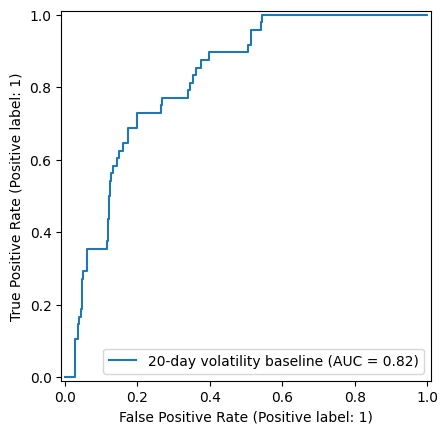

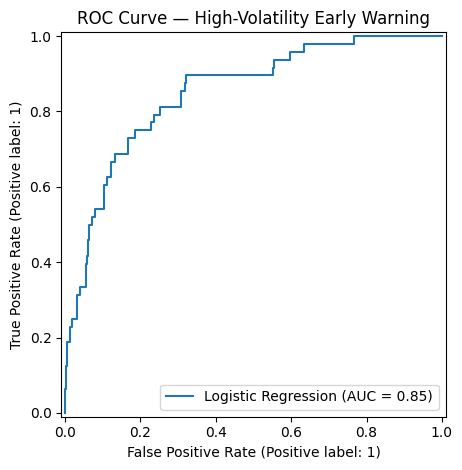

<Figure size 700x500 with 0 Axes>

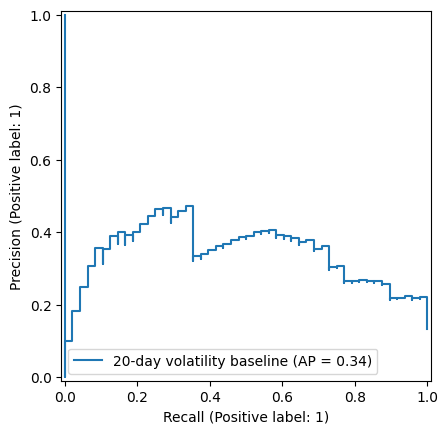

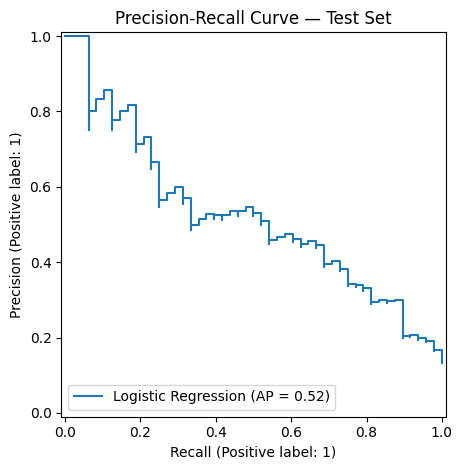

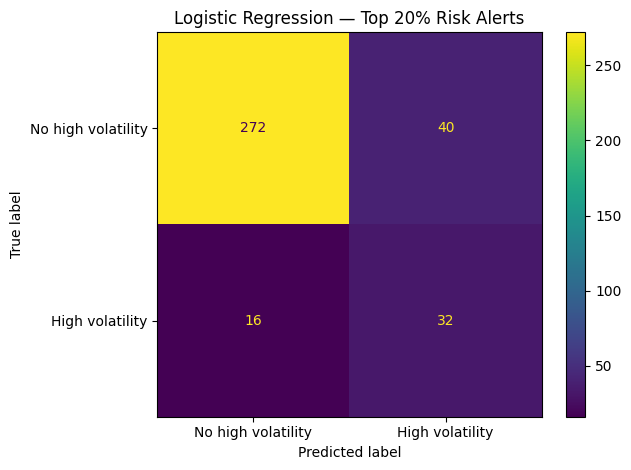

In [23]:

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use the final test predictions already calculated
y_true = y_test
lr_scores = test_scores
baseline_scores = baseline_scores

# Apply the same top-20% alert rule
cutoff = np.quantile(lr_scores, 0.80)
lr_alerts = (lr_scores >= cutoff).astype(int)

# 1. ROC curve
plt.figure(figsize=(7, 5))
RocCurveDisplay.from_predictions(
    y_true, baseline_scores,
    name="20-day volatility baseline"
)
RocCurveDisplay.from_predictions(
    y_true, lr_scores,
    name="Logistic Regression"
)
plt.title("ROC Curve — High-Volatility Early Warning")
plt.tight_layout()
plt.show()

# 2. Precision-recall curve
plt.figure(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(
    y_true, baseline_scores,
    name="20-day volatility baseline"
)
PrecisionRecallDisplay.from_predictions(
    y_true, lr_scores,
    name="Logistic Regression"
)
plt.title("Precision-Recall Curve — Test Set")
plt.tight_layout()
plt.show()

# 3. Confusion matrix at the top-20% alert threshold
cm = confusion_matrix(y_true, lr_alerts, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No high volatility", "High volatility"]
)
disp.plot(values_format="d")
plt.title("Logistic Regression — Top 20% Risk Alerts")
plt.tight_layout()
plt.show()


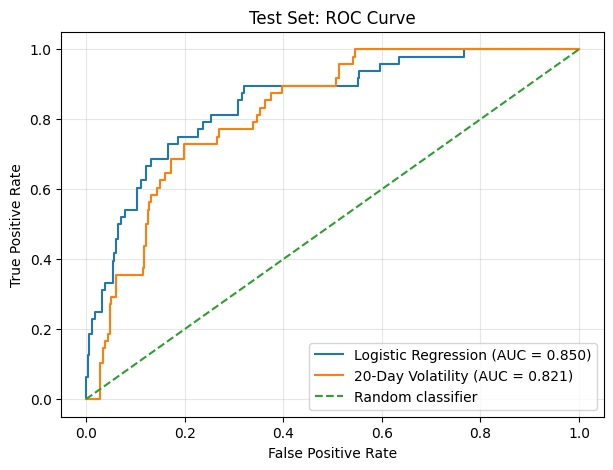

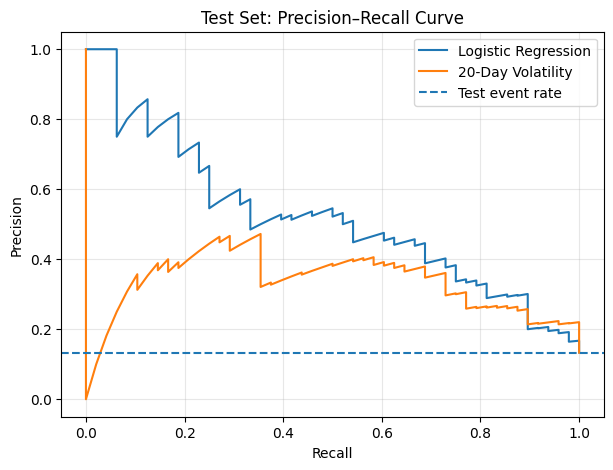

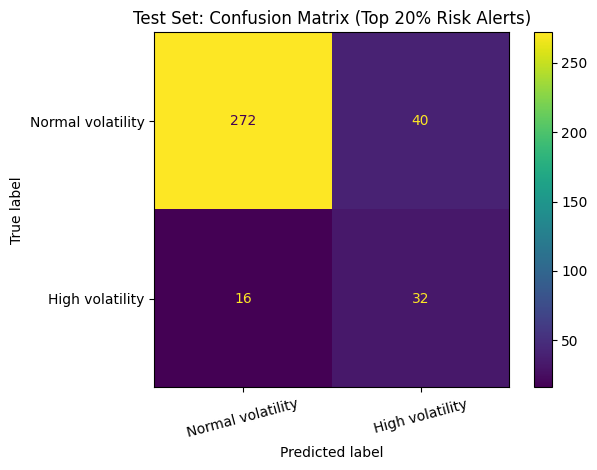

In [24]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use the test-set results
y_true = y_test
lr_scores = np.asarray(test_scores)
baseline_scores = np.asarray(test_exp["Volatility_20D"])

# 1. ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_true, lr_scores)
fpr_base, tpr_base, _ = roc_curve(y_true, baseline_scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc(fpr_lr, tpr_lr):.3f})")
plt.plot(fpr_base, tpr_base, label=f"20-Day Volatility (AUC = {auc(fpr_base, tpr_base):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test Set: ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Precision–Recall Curve
precision_lr, recall_lr, _ = precision_recall_curve(y_true, lr_scores)
precision_base, recall_base, _ = precision_recall_curve(y_true, baseline_scores)

plt.figure(figsize=(7, 5))
plt.plot(recall_lr, precision_lr, label="Logistic Regression")
plt.plot(recall_base, precision_base, label="20-Day Volatility")
plt.axhline(np.mean(y_true), linestyle="--", label="Test event rate")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Test Set: Precision–Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 3. Confusion Matrix at a Top-20% Risk Alert Threshold
cutoff = np.quantile(lr_scores, 0.80)
lr_alerts = (lr_scores >= cutoff).astype(int)

cm = confusion_matrix(y_true, lr_alerts, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal volatility", "High volatility"]
)

disp.plot(values_format="d")
plt.title("Test Set: Confusion Matrix (Top 20% Risk Alerts)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [25]:

from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

# 1. Check each split
for name, split in [
    ("Train", train_exp),
    ("Validation", val_exp),
    ("Test", test_exp)
]:
    print(f"\n{name}")
    print("Rows:", len(split))
    print("Date range:", split.index.min().date(), "to", split.index.max().date())
    print("Positive labels:", int(split["High_Volatility"].sum()))
    print("Event rate:", round(split["High_Volatility"].mean(), 4))

# 2. Recalculate model scores directly from the fitted model
original_features = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

val_scores_check = logistic_model.predict_proba(
    val_exp[original_features]
)[:, 1]

test_scores_check = logistic_model.predict_proba(
    test_exp[original_features]
)[:, 1]

# 3. Recalculate validation and test metrics
for name, split, scores in [
    ("Validation", val_exp, val_scores_check),
    ("Test", test_exp, test_scores_check)
]:
    y = split["High_Volatility"].to_numpy()
    print(f"\n{name} metrics")
    print("ROC-AUC:", round(roc_auc_score(y, scores), 4))
    print("Average Precision:", round(average_precision_score(y, scores), 4))
    print("Score range:", round(scores.min(), 4), "to", round(scores.max(), 4))

# 4. Check alignment and leakage risks
print("\nIntegrity checks")
print("Test rows match score count:", len(test_exp) == len(test_scores_check))
print("Duplicate dates in test:", test_exp.index.duplicated().sum())
print("Target accidentally included as a feature:",
      "High_Volatility" in original_features or
      "Future_5D_Volatility" in original_features)
print("Feature list:", original_features)



Train
Rows: 1674
Date range: 2017-01-18 to 2023-11-02
Positive labels: 341
Event rate: 0.2037

Validation
Rows: 355
Date range: 2023-11-10 to 2025-04-25
Positive labels: 45
Event rate: 0.1268

Test
Rows: 360
Date range: 2025-05-06 to 2026-10-15
Positive labels: 48
Event rate: 0.1333

Validation metrics
ROC-AUC: 0.5032
Average Precision: 0.1731
Score range: 0.0508 to 0.9991

Test metrics
ROC-AUC: 0.8496
Average Precision: 0.5237
Score range: 0.0827 to 0.9594

Integrity checks
Test rows match score count: True
Duplicate dates in test: 0
Target accidentally included as a feature: False
Feature list: ['Return_1D', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'Intraday_Range', 'Open_Close_Return', 'Volume_Change']


In [26]:

from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

# Use the same fitted model and same 8 features
feature_cols = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

results = []

for name, split in [("Validation", val_exp), ("Test", test_exp)]:
    y = split["High_Volatility"].to_numpy()

    lr_scores = logistic_model.predict_proba(
        split[feature_cols]
    )[:, 1]

    baseline = split["Volatility_20D"].to_numpy()

    results.append({
        "Period": name,
        "LR_AUC": roc_auc_score(y, lr_scores),
        "LR_AP": average_precision_score(y, lr_scores),
        "Volatility_Baseline_AUC": roc_auc_score(y, baseline),
        "Volatility_Baseline_AP": average_precision_score(y, baseline),
        "Correlation_Vol20D_Target": np.corrcoef(
            split["Volatility_20D"], split["Future_5D_Volatility"]
        )[0, 1]
    })

print(pd.DataFrame(results).round(4).to_string(index=False))

# Compare feature distributions between validation and test
print("\nFeature distribution comparison:")
comparison = pd.DataFrame({
    "Validation_Median": val_exp[feature_cols].median(),
    "Test_Median": test_exp[feature_cols].median(),
    "Validation_Mean": val_exp[feature_cols].mean(),
    "Test_Mean": test_exp[feature_cols].mean()
})
print(comparison.round(5))

# Check whether high-volatility labels match the stated threshold
print("\nTarget threshold check:")
print("Threshold:", threshold)
for name, split in [("Validation", val_exp), ("Test", test_exp)]:
    expected = (
        split["Future_5D_Volatility"] > threshold
    ).astype(int)
    mismatches = (expected != split["High_Volatility"]).sum()
    print(name, "label mismatches:", int(mismatches))


    Period  LR_AUC  LR_AP  Volatility_Baseline_AUC  Volatility_Baseline_AP  Correlation_Vol20D_Target
Validation  0.5032 0.1731                   0.4553                  0.1137                    -0.1318
      Test  0.8496 0.5237                   0.8209                  0.3403                     0.5235

Feature distribution comparison:
                   Validation_Median  Test_Median  Validation_Mean  Test_Mean
Price                                                                        
Return_1D                    0.00087     -0.00012          0.00059   -0.00017
Return_5D                    0.00429     -0.00228          0.00322   -0.00088
Return_20D                   0.01038      0.00483          0.01091   -0.00127
Volatility_5D                0.00674      0.00608          0.00742    0.00706
Volatility_20D               0.00730      0.00631          0.00812    0.00743
Intraday_Range               0.00863      0.00814          0.01012    0.00898
Open_Close_Return           -0.00024

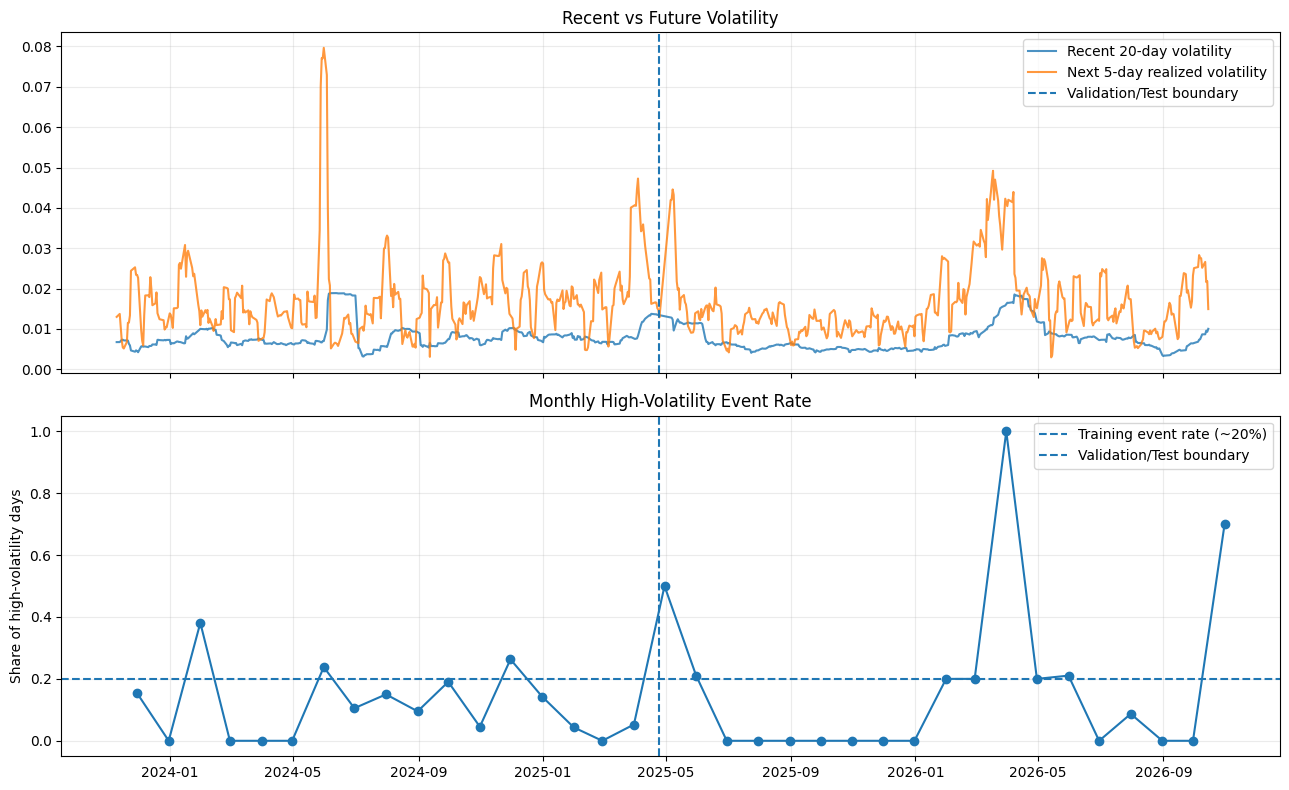

Train correlation: 0.5967
Validation correlation: -0.1318
Test correlation: 0.5235


In [27]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Combine validation and test in chronological order
combined = pd.concat([val_exp, test_exp]).sort_index().copy()

# 1. Compare recent volatility with future realized volatility
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axes[0].plot(
    combined.index, combined["Volatility_20D"],
    label="Recent 20-day volatility", alpha=0.8
)
axes[0].plot(
    combined.index, combined["Future_5D_Volatility"],
    label="Next 5-day realized volatility", alpha=0.8
)
axes[0].axvline(val_exp.index.max(), linestyle="--",
                label="Validation/Test boundary")
axes[0].set_title("Recent vs Future Volatility")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Monthly high-volatility event rate
monthly_rate = combined["High_Volatility"].resample("ME").mean()
axes[1].plot(monthly_rate.index, monthly_rate.values, marker="o")
axes[1].axhline(0.20, linestyle="--", label="Training event rate (~20%)")
axes[1].axvline(val_exp.index.max(), linestyle="--",
                label="Validation/Test boundary")
axes[1].set_title("Monthly High-Volatility Event Rate")
axes[1].set_ylabel("Share of high-volatility days")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# 2. Calculate correlations separately by period
for name, split in [
    ("Train", train_exp),
    ("Validation", val_exp),
    ("Test", test_exp)
]:
    corr = split[
        ["Volatility_20D", "Future_5D_Volatility"]
    ].corr().iloc[0, 1]
    print(f"{name} correlation: {corr:.4f}")


In [28]:

from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

# Recalculate predictions in chronological order
test_check = test_exp.copy()
test_check["LR_Score"] = logistic_model.predict_proba(
    test_check[feature_cols]
)[:, 1]
test_check["Baseline_Score"] = test_check["Volatility_20D"]

# Evaluate by calendar quarter
test_check["Quarter"] = test_check.index.to_period("Q")

rows = []
for quarter, group in test_check.groupby("Quarter"):
    y = group["High_Volatility"].to_numpy()

    # AUC requires both positive and negative examples
    if len(np.unique(y)) < 2:
        lr_auc = np.nan
        base_auc = np.nan
    else:
        lr_auc = roc_auc_score(y, group["LR_Score"])
        base_auc = roc_auc_score(y, group["Baseline_Score"])

    rows.append({
        "Quarter": str(quarter),
        "Observations": len(group),
        "High_Volatility_Days": int(y.sum()),
        "Event_Rate": round(y.mean(), 3),
        "LR_AUC": round(lr_auc, 3) if not np.isnan(lr_auc) else np.nan,
        "Baseline_AUC": round(base_auc, 3) if not np.isnan(base_auc) else np.nan
    })

quarterly_results = pd.DataFrame(rows)
print(quarterly_results.to_string(index=False))


Quarter  Observations  High_Volatility_Days  Event_Rate  LR_AUC  Baseline_AUC
 2025Q2            40                     4       0.100   0.896         0.854
 2025Q3            64                     0       0.000     NaN           NaN
 2025Q4            62                     0       0.000     NaN           NaN
 2026Q1            59                    27       0.458   0.868         0.868
 2026Q2            60                     8       0.133   0.733         0.731
 2026Q3            65                     2       0.031   0.286         0.635
 2026Q4            10                     7       0.700   0.476         0.000


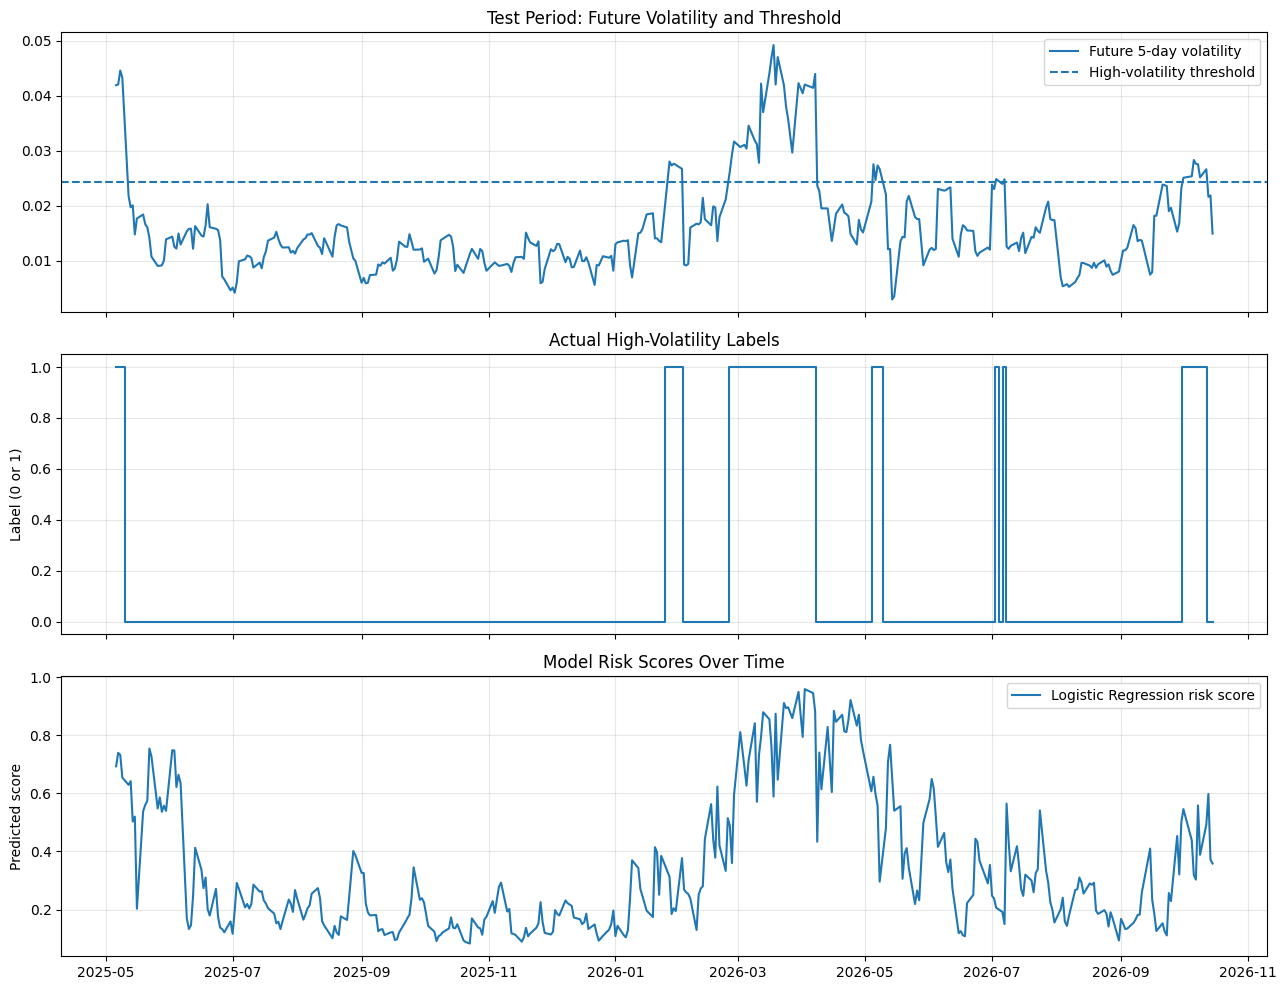

Highest future-volatility observations:
Price       Future_5D_Volatility  High_Volatility  LR_Score
Date                                                       
2026-03-18                0.0492                1    0.5890
2026-03-20                0.0470                1    0.6473
2026-03-17                0.0469                1    0.7602
2025-05-08                0.0446                1    0.7325
2026-03-16                0.0441                1    0.8556
2026-04-07                0.0440                1    0.8821
2025-05-09                0.0432                1    0.6545
2026-03-30                0.0423                1    0.9499
2026-03-12                0.0422                1    0.7954
2025-05-07                0.0420                1    0.7399


In [29]:

import matplotlib.pyplot as plt
import pandas as pd

audit = test_exp.copy()

audit["LR_Score"] = logistic_model.predict_proba(
    audit[feature_cols]
)[:, 1]

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].plot(
    audit.index, audit["Future_5D_Volatility"],
    label="Future 5-day volatility"
)
axes[0].axhline(
    threshold, linestyle="--",
    label="High-volatility threshold"
)
axes[0].set_title("Test Period: Future Volatility and Threshold")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].step(
    audit.index, audit["High_Volatility"],
    where="mid"
)
axes[1].set_title("Actual High-Volatility Labels")
axes[1].set_ylabel("Label (0 or 1)")
axes[1].grid(alpha=0.3)

axes[2].plot(
    audit.index, audit["LR_Score"],
    label="Logistic Regression risk score"
)
axes[2].set_title("Model Risk Scores Over Time")
axes[2].set_ylabel("Predicted score")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Highest future-volatility observations:")
print(
    audit.nlargest(10, "Future_5D_Volatility")[
        ["Future_5D_Volatility", "High_Volatility", "LR_Score"]
    ].round(4).to_string()
)


In [30]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

features = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

# Combine the existing chronological splits.
# The volatility threshold remains fixed from the original training period.
all_data = pd.concat([train_exp, val_exp, test_exp]).sort_index()
all_data = all_data.loc[~all_data.index.duplicated(keep="first")].copy()

# Evaluate each quarter in the existing test period.
walk_forward_results = []

for quarter in test_exp.index.to_period("Q").unique():
    quarter_mask = test_exp.index.to_period("Q") == quarter
    evaluation = test_exp.loc[quarter_mask].copy()

    # Use only observations before this quarter.
    # Remove the last 5 past rows to reduce overlap between training
    # targets and the evaluation period.
    first_eval_date = evaluation.index.min()
    past = all_data.loc[all_data.index < first_eval_date].iloc[:-5].copy()

    if len(past) < 200 or evaluation["High_Volatility"].nunique() < 2:
        print(f"Skipping {quarter}: insufficient training data or only one target class.")
        continue

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

    model.fit(past[features], past["High_Volatility"])
    scores = model.predict_proba(evaluation[features])[:, 1]
    y = evaluation["High_Volatility"].to_numpy()

    walk_forward_results.append({
        "Quarter": str(quarter),
        "Train_Rows": len(past),
        "Evaluation_Rows": len(evaluation),
        "Positive_Days": int(y.sum()),
        "Event_Rate": round(y.mean(), 3),
        "ROC_AUC": round(roc_auc_score(y, scores), 3),
        "Average_Precision": round(average_precision_score(y, scores), 3)
    })

walk_forward_table = pd.DataFrame(walk_forward_results)
print("\nWalk-forward results:")
print(walk_forward_table.to_string(index=False))


Skipping 2025Q3: insufficient training data or only one target class.
Skipping 2025Q4: insufficient training data or only one target class.

Walk-forward results:
Quarter  Train_Rows  Evaluation_Rows  Positive_Days  Event_Rate  ROC_AUC  Average_Precision
 2025Q2        2024               40              4       0.100    0.868              0.328
 2026Q1        2190               59             27       0.458    0.865              0.894
 2026Q2        2249               60              8       0.133    0.719              0.486
 2026Q3        2309               65              2       0.031    0.190              0.028
 2026Q4        2374               10              7       0.700    0.429              0.685


In [31]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

features = [
    "Return_1D", "Return_5D", "Return_20D",
    "Volatility_5D", "Volatility_20D",
    "Intraday_Range", "Open_Close_Return", "Volume_Change"
]

all_data = pd.concat([train_exp, val_exp, test_exp]).sort_index()
all_data = all_data.loc[~all_data.index.duplicated(keep="first")].copy()

model_results = []

for quarter in test_exp.index.to_period("Q").unique():
    evaluation = test_exp.loc[
        test_exp.index.to_period("Q") == quarter
    ].copy()

    past = all_data.loc[all_data.index < evaluation.index.min()].iloc[:-5].copy()
    y_test_q = evaluation["High_Volatility"].to_numpy()

    if len(past) < 200 or len(np.unique(y_test_q)) < 2:
        continue

    models = {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                class_weight="balanced", max_iter=2000, random_state=42
            ))
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=300, min_samples_leaf=10,
                class_weight="balanced", random_state=42, n_jobs=-1
            ))
        ]),
        "XGBoost": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBClassifier(
                n_estimators=200, max_depth=2, learning_rate=0.03,
                subsample=0.8, colsample_bytree=0.8,
                reg_lambda=5, eval_metric="logloss",
                random_state=42
            ))
        ])
    }

    for model_name, model in models.items():
        model.fit(past[features], past["High_Volatility"])
        scores = model.predict_proba(evaluation[features])[:, 1]

        model_results.append({
            "Quarter": str(quarter),
            "Model": model_name,
            "Observations": len(evaluation),
            "Positive_Days": int(y_test_q.sum()),
            "ROC_AUC": round(roc_auc_score(y_test_q, scores), 3),
            "Average_Precision": round(
                average_precision_score(y_test_q, scores), 3
            )
        })

comparison = pd.DataFrame(model_results)
print(comparison.to_string(index=False))


Quarter               Model  Observations  Positive_Days  ROC_AUC  Average_Precision
 2025Q2 Logistic Regression            40              4    0.868              0.328
 2025Q2       Random Forest            40              4    0.799              0.279
 2025Q2             XGBoost            40              4    0.757              0.264
 2026Q1 Logistic Regression            59             27    0.865              0.894
 2026Q1       Random Forest            59             27    0.874              0.906
 2026Q1             XGBoost            59             27    0.865              0.901
 2026Q2 Logistic Regression            60              8    0.719              0.486
 2026Q2       Random Forest            60              8    0.755              0.552
 2026Q2             XGBoost            60              8    0.772              0.571
 2026Q3 Logistic Regression            65              2    0.190              0.028
 2026Q3       Random Forest            65              2    0.802

In [32]:

# Final walk-forward results table
final_results = comparison.copy()

final_results = final_results.rename(columns={
    "Quarter": "Evaluation Quarter",
    "Model": "Model",
    "Observations": "Test Observations",
    "Positive_Days": "High-Volatility Days",
    "ROC_AUC": "ROC-AUC",
    "Average_Precision": "Average Precision"
})

final_results = final_results.sort_values(
    ["Evaluation Quarter", "Model"]
).reset_index(drop=True)

display(final_results)

# Save results for the project repository
final_results.to_csv("walk_forward_results.csv", index=False)

print("Saved: walk_forward_results.csv")


,Evaluation Quarter,Model,Test Observations,High-Volatility Days,ROC-AUC,Average Precision
0,2025Q2,Logistic Regression,40,4,0.868,0.328
1,2025Q2,Random Forest,40,4,0.799,0.279
2,2025Q2,XGBoost,40,4,0.757,0.264
3,2026Q1,Logistic Regression,59,27,0.865,0.894
4,2026Q1,Random Forest,59,27,0.874,0.906
5,2026Q1,XGBoost,59,27,0.865,0.901
6,2026Q2,Logistic Regression,60,8,0.719,0.486
7,2026Q2,Random Forest,60,8,0.755,0.552
8,2026Q2,XGBoost,60,8,0.772,0.571
9,2026Q3,Logistic Regression,65,2,0.190,0.028


Saved: walk_forward_results.csv


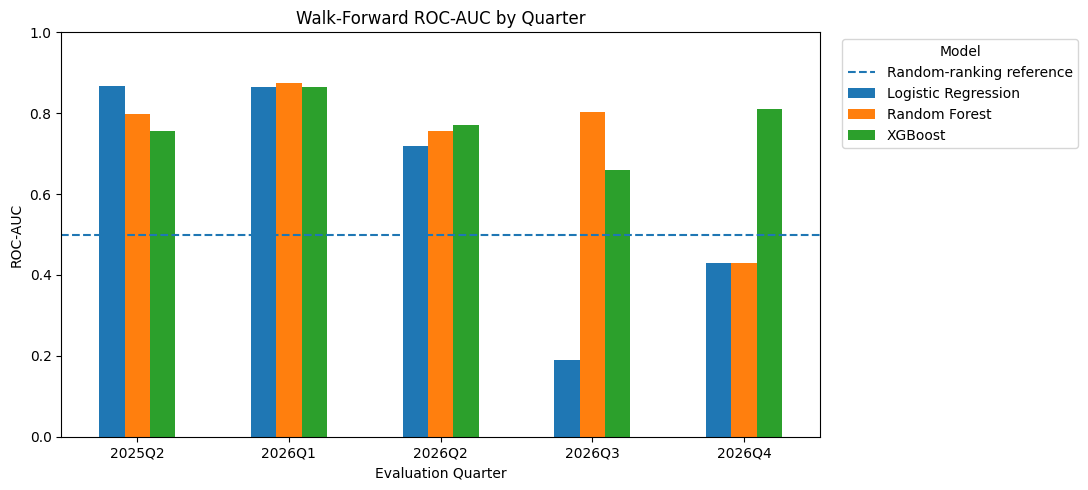

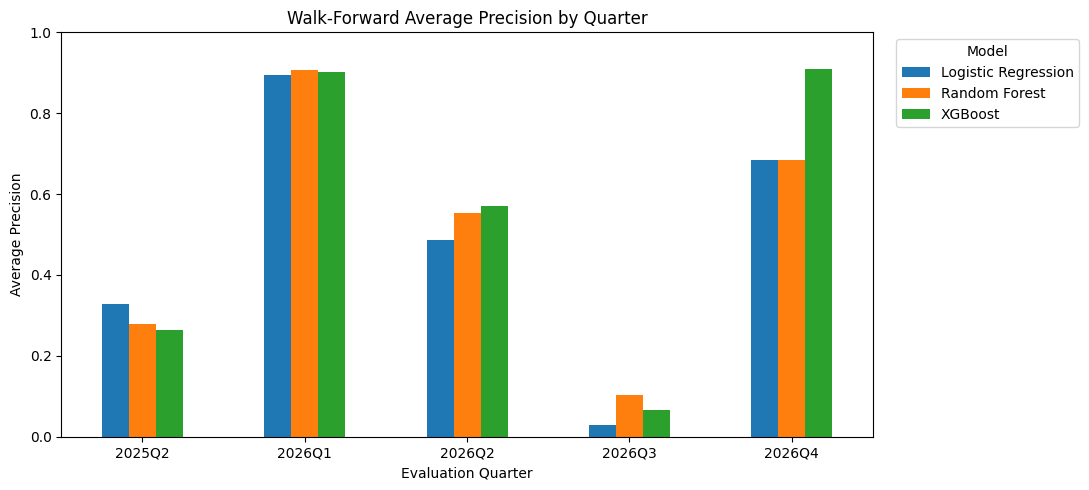

Both charts saved successfully.


In [34]:

import matplotlib.pyplot as plt
import pandas as pd

# Rebuild the results table directly in Python
final_results = pd.DataFrame([
    ["2025Q2", "Logistic Regression", 40, 4, 0.868, 0.328],
    ["2025Q2", "Random Forest", 40, 4, 0.799, 0.279],
    ["2025Q2", "XGBoost", 40, 4, 0.757, 0.264],
    ["2026Q1", "Logistic Regression", 59, 27, 0.865, 0.894],
    ["2026Q1", "Random Forest", 59, 27, 0.874, 0.906],
    ["2026Q1", "XGBoost", 59, 27, 0.865, 0.901],
    ["2026Q2", "Logistic Regression", 60, 8, 0.719, 0.486],
    ["2026Q2", "Random Forest", 60, 8, 0.755, 0.552],
    ["2026Q2", "XGBoost", 60, 8, 0.772, 0.571],
    ["2026Q3", "Logistic Regression", 65, 2, 0.190, 0.028],
    ["2026Q3", "Random Forest", 65, 2, 0.802, 0.104],
    ["2026Q3", "XGBoost", 65, 2, 0.659, 0.067],
    ["2026Q4", "Logistic Regression", 10, 7, 0.429, 0.685],
    ["2026Q4", "Random Forest", 10, 7, 0.429, 0.685],
    ["2026Q4", "XGBoost", 10, 7, 0.810, 0.909]
], columns=[
    "Evaluation Quarter", "Model", "Test Observations",
    "High-Volatility Days", "ROC-AUC", "Average Precision"
])

# Plot ROC-AUC
auc_plot = final_results.pivot(
    index="Evaluation Quarter", columns="Model", values="ROC-AUC"
)

ax = auc_plot.plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
ax.axhline(0.5, linestyle="--", label="Random-ranking reference")
ax.set_title("Walk-Forward ROC-AUC by Quarter")
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("Evaluation Quarter")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("walk_forward_auc.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot Average Precision
ap_plot = final_results.pivot(
    index="Evaluation Quarter", columns="Model", values="Average Precision"
)

ax = ap_plot.plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
ax.set_title("Walk-Forward Average Precision by Quarter")
ax.set_ylabel("Average Precision")
ax.set_xlabel("Evaluation Quarter")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "walk_forward_average_precision.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("Both charts saved successfully.")


##  Final Model Evaluation and Research Findings

### Research Objective
This project investigates whether historical price movements and volatility indicators can help identify periods of elevated volatility in the NIFTY 50 index over the next five trading sessions.

### Methodology
- **Data:** Historical daily NIFTY 50 market data.
- **Features:** Eight indicators derived from historical returns, rolling volatility, intraday price ranges, and volume changes.
- **Target:** An indicator identifying whether future five-session volatility exceeds the 80th percentile of the training-period target distribution.
- **Models:** Logistic Regression, Random Forest, and XGBoost.
- **Evaluation:** Chronological data splitting and expanding-window walk-forward evaluation.

### Main Findings
1. Model performance varied considerably across evaluation quarters.
2. No single model consistently outperformed the others across all evaluated periods.
3. Random Forest and XGBoost performed competitively in some quarters, while Logistic Regression performed well in others.
4. Results were particularly unstable in quarters with very few positive observations.

### Limitations
- The analysis uses one index and a limited set of engineered features.
- Market conditions and the frequency of high-volatility events change over time.
- Several quarterly evaluation periods contain few positive observations, making their performance estimates uncertain.
- The test-period results have been inspected during project development and should not be considered an untouched final holdout.
- The findings are exploratory and do not establish profitability or demonstrate that the model is ready for live trading.

### Conclusion
The analysis illustrates the challenges of forecasting elevated market volatility and the importance of chronological evaluation. Further research should examine additional market indicators, longer evaluation periods, and robustness across different market regimes.

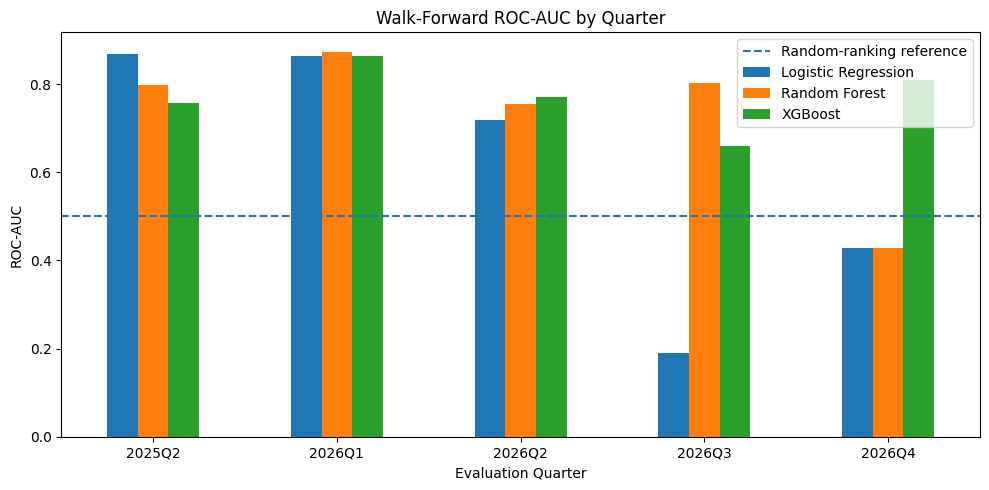

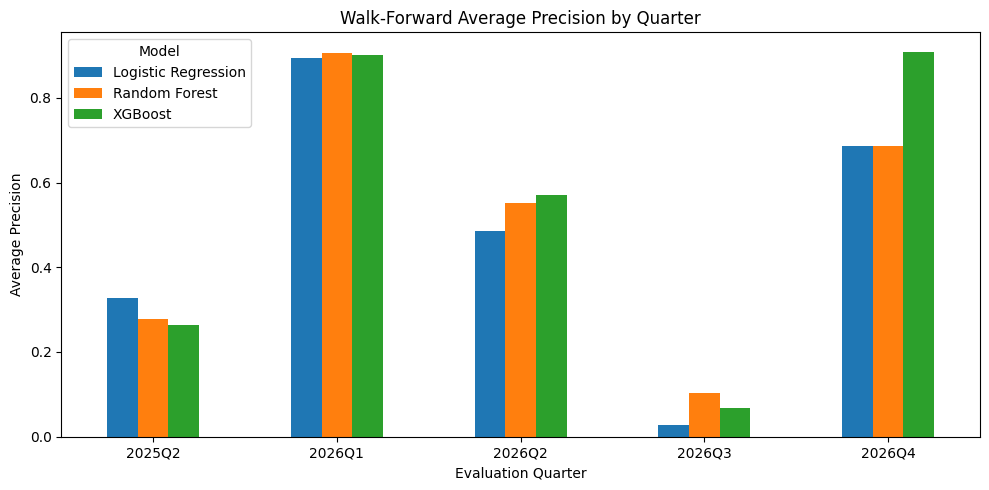

MODEL PERFORMANCE SUMMARY


,Model,Evaluated_Quarters,Mean_ROC_AUC,Mean_Average_Precision
0,Logistic Regression,5,0.614,0.484
1,Random Forest,5,0.732,0.505
2,XGBoost,5,0.773,0.542



Files saved successfully:
results/walk_forward_results.csv
results/model_performance_summary.csv
results/walk_forward_auc.png
results/walk_forward_average_precision.png


In [37]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Create results folder
os.makedirs("results", exist_ok=True)

# Use the actual column names in your DataFrame
summary = (
    final_results.groupby("Model")
    .agg(
        Evaluated_Quarters=("Evaluation Quarter", "nunique"),
        Mean_ROC_AUC=("ROC-AUC", "mean"),
        Mean_Average_Precision=("Average Precision", "mean")
    )
    .reset_index()
)

# Save both evaluation tables
final_results.to_csv("results/walk_forward_results.csv", index=False)
summary.to_csv("results/model_performance_summary.csv", index=False)

# Plot and save ROC-AUC chart
auc_pivot = final_results.pivot(
    index="Evaluation Quarter",
    columns="Model",
    values="ROC-AUC"
)

ax = auc_pivot.plot(kind="bar", figsize=(10, 5))
ax.axhline(0.5, linestyle="--", label="Random-ranking reference")
ax.set_title("Walk-Forward ROC-AUC by Quarter")
ax.set_xlabel("Evaluation Quarter")
ax.set_ylabel("ROC-AUC")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("results/walk_forward_auc.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Plot and save Average Precision chart
ap_pivot = final_results.pivot(
    index="Evaluation Quarter",
    columns="Model",
    values="Average Precision"
)

ax = ap_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Walk-Forward Average Precision by Quarter")
ax.set_xlabel("Evaluation Quarter")
ax.set_ylabel("Average Precision")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "results/walk_forward_average_precision.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Display summary and confirm files
print("MODEL PERFORMANCE SUMMARY")
display(summary.round(3))

print("\nFiles saved successfully:")
for filename in [
    "results/walk_forward_results.csv",
    "results/model_performance_summary.csv",
    "results/walk_forward_auc.png",
    "results/walk_forward_average_precision.png"
]:
    print(filename)


In [38]:

import shutil
import os

assert os.path.exists("results/walk_forward_results.csv"), (
    "The results files were not found. Run the previous cell first."
)

shutil.make_archive(
    "volatility_project_results",
    "zip",
    root_dir="results"
)

print("Created volatility_project_results.zip")


Created volatility_project_results.zip


In [39]:

readme = r"""# Indian Equity Volatility Early-Warning Model

## Overview
This project investigates whether historical market data can help identify periods of elevated volatility in India's NIFTY 50 index over the next five trading sessions.

It compares three machine-learning approaches with a chronological walk-forward evaluation framework.

## Research Question
Can historical returns, rolling volatility, intraday price ranges, and volume-related indicators help rank upcoming high-volatility periods?

## Data
- **Market:** NIFTY 50 index (`^NSEI`)
- **Source:** Yahoo Finance via `yfinance`
- **Frequency:** Daily
- **Historical window:** Approximately 10 years, depending on data availability when the notebook is run.

## Target Definition
Future five-session volatility is calculated from the squared daily log returns over the next five trading sessions. A high-volatility event is defined as future volatility exceeding the 80th percentile of the training-period target distribution.

## Features
The selected eight features are:
- One-day log return
- Five-day return
- Twenty-day return
- Five-day rolling volatility
- Twenty-day rolling volatility
- Intraday high-low range
- Open-to-close return
- Volume change

## Models
- Logistic Regression
- Random Forest
- XGBoost

## Evaluation
The notebook uses chronological splits and expanding-window walk-forward evaluation. ROC-AUC and Average Precision are reported by evaluation quarter.

### Walk-Forward Summary

| Model | Mean ROC-AUC | Mean Average Precision |
|---|---:|---:|
| Logistic Regression | 0.614 | 0.484 |
| Random Forest | 0.732 | 0.505 |
| XGBoost | 0.773 | 0.542 |

These averages cover only five evaluated quarters. The quarters differ in sample size and event frequency, so the averages should be interpreted cautiously. Some quarters contain very few positive observations.

## Repository Contents
- `Indian_Equity_Volatility_Model.ipynb` — analysis, feature engineering, modelling, and evaluation.
- `results/walk_forward_results.csv` — quarterly model metrics.
- `results/model_performance_summary.csv` — descriptive summary across evaluated quarters.
- `results/walk_forward_auc.png` — quarterly ROC-AUC chart.
- `results/walk_forward_average_precision.png` — quarterly Average Precision chart.

## Limitations
- The study focuses on a single market index.
- Market regimes and the frequency of high-volatility events change over time.
- Metrics based on small quarterly samples are uncertain.
- Test-period results were inspected during development and are not an untouched final holdout.
- Predictive ranking does not establish profitability or demonstrate readiness for live trading.

## Reproducibility
Open the notebook in Google Colab and run its cells in order. The notebook installs its Python dependencies and retrieves historical data using `yfinance`. Results may change when the data source is updated.

## Disclaimer
This project is for educational and research purposes only. It is not financial advice or a trading recommendation.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md created successfully.")


README.md created successfully.


In [40]:

from google.colab import files
import os

# Download the README
files.download("README.md")

# Download the results ZIP
files.download("volatility_project_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>